# 🚗 VISION: RT-DETRv2-S Night & Distant-Object Optimization Pipeline (V3 Production)
### تحسين دقة الرصد الليلي والأجسام البعيدة ومضاعفة المطبات

تم التحقق من الجاهزية الهندسية الكاملة وتثبيت النقاط التالية:
1. **وضع الـ Fine-Tuning الصحيح (`-t` / `--tuning`):** استخدام خيار `-t` بدلاً من `-r` لتحميل أوزان `best.pth` (86.66% mAP) مع تصفير عداد الـ Epoch ليبدأ التدريب من 0 إلى 20 بشكل نظيف دون تضارب مع إيبوكات الموديل السابقة.
2. **الحفاظ التام على بنية المعمارية (100% Architecture Match):** قراءة ملف `rtdetrv2_adas_baseline.yml` نفسه ووراثة كافة تفاصيل (PResNet18, HybridEncoder, RTDETRTransformerv2) دون أي تغيير هيكلي.
3. **أمان إعادة التشغيل (Idempotent Augmentation):** تنظيف أي صور اصطناعية سابقة قبل التوليد، لضمان عدم تكرار أو مضاعفة الصور في حال أُعيد تشغيل الخلية رقم 5.
4. **حصر الانعكاس الضوئي على اللوحات العاكسة فقط (Selective Retro-reflection):** تطبيق لمعان أنوار السيارات فقط على اللوحات المرورية (`REFLECTIVE_SIGN_CLASSES`) مع استبعاد المشاة والمطبات والحصى تماماً.
5. **فلترة صور النهار الحقيقية فقط (Luminance Filter):** قياس متوسط سطوع القنوات واستبعاد أي صورة مظلمة أو ليلية مسبقاً.
6. **مضاعفة حقيقية لمطبات النهار (3x):** (أصلية + نسخة ليلية + نسخة نهارية بتباين محسن).
7. **تصدير ONNX الموثوق للأندرويد:** مع الترتيب الصحيح `[width, height]`.


In [ ]:
# 1. ربط Google Drive وفحص كرت الشاشة
from google.colab import drive
import torch
import os

drive.mount('/content/drive')

print("=" * 60)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2), "GB")
print("=" * 60)


Mounted at /content/drive
CUDA Available: True
GPU Device: Tesla T4
VRAM: 14.56 GB


In [ ]:
# 2. تثبيت المكتبات وتجهيز مستودع RT-DETR
import os

%cd /content
if not os.path.exists("/content/RT-DETR"):
    os.system("git clone https://github.com/lyuwenyu/RT-DETR.git")

!pip install -q onnx onnxsim onnxruntime albumentations opencv-python matplotlib pycocotools
print("Environment ready!")


/content
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 68.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 50.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 66.2 MB/s eta 0:00:00
Environment ready!


In [ ]:
# 3. فك ضغط الداتا الأصلية (إذا لم تكن مفكوكة مسبقاً)
import zipfile
import os

zip_path = "/content/drive/MyDrive/Offline Arabic ADAS.coco.zip"
extract_path = "/content/adas_coco"

if not os.path.exists(extract_path):
    print("Extracting dataset from Drive...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extracted successfully to:", extract_path)
else:
    print("Dataset already extracted at:", extract_path)


Extracting dataset from Drive...
Extracted successfully to: /content/adas_coco


In [ ]:
# 4. توحيد الفئات الـ 14 من 0 إلى 13 ونقل الصور إلى adas_coco_rtdetr
import json
import os
import shutil

source_root = "/content/adas_coco"
target_root = "/content/adas_coco_rtdetr"
splits = ["train", "valid", "test"]

category_mapping = {
    1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6,
    8: 7, 9: 8, 10: 9, 11: 10, 12: 11, 13: 12, 14: 13
}

new_categories = [
    {"id": 0, "name": "loose_gravel", "supercategory": "ADAS"},
    {"id": 1, "name": "no_entry", "supercategory": "ADAS"},
    {"id": 2, "name": "no_parking_waiting", "supercategory": "ADAS"},
    {"id": 3, "name": "pedestrian", "supercategory": "ADAS"},
    {"id": 4, "name": "pedestrian_crossing_sign", "supercategory": "ADAS"},
    {"id": 5, "name": "speed_100", "supercategory": "ADAS"},
    {"id": 6, "name": "speed_30", "supercategory": "ADAS"},
    {"id": 7, "name": "speed_40", "supercategory": "ADAS"},
    {"id": 8, "name": "speed_50", "supercategory": "ADAS"},
    {"id": 9, "name": "speed_60", "supercategory": "ADAS"},
    {"id": 10, "name": "speed_80", "supercategory": "ADAS"},
    {"id": 11, "name": "speed_bump", "supercategory": "ADAS"},
    {"id": 12, "name": "stoop_sign", "supercategory": "ADAS"},
    {"id": 13, "name": "traffic_signal", "supercategory": "ADAS"}
]

os.makedirs(target_root, exist_ok=True)

for split in splits:
    source_dir = os.path.join(source_root, split)
    target_dir = os.path.join(target_root, split)
    os.makedirs(target_dir, exist_ok=True)

    for filename in os.listdir(source_dir):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            shutil.copy2(os.path.join(source_dir, filename), os.path.join(target_dir, filename))

    source_json = os.path.join(source_dir, "_annotations.coco.json")
    target_json = os.path.join(target_dir, "_annotations.coco.json")

    with open(source_json, "r", encoding="utf-8") as f:
        coco = json.load(f)

    for ann in coco["annotations"]:
        old_id = ann["category_id"]
        if old_id in category_mapping:
            ann["category_id"] = category_mapping[old_id]

    coco["categories"] = new_categories

    with open(target_json, "w", encoding="utf-8") as f:
        json.dump(coco, f, ensure_ascii=False)

    print(f"[{split}] {len(coco['images'])} images, {len(coco['annotations'])} annotations.")

print("\nBase conversion complete.")


[train] 6191 images, 8520 annotations.
[valid] 1767 images, 2405 annotations.
[test] 884 images, 1278 annotations.

Base conversion complete.


Clean original train images: 6191
Clean images containing speed bumps: 121
Verified daytime images: 5136 out of 6191
Generated 1986 augmented images (Night + Daytime Speed Bumps).
Total train images now: 8177
Total annotations now: 11340


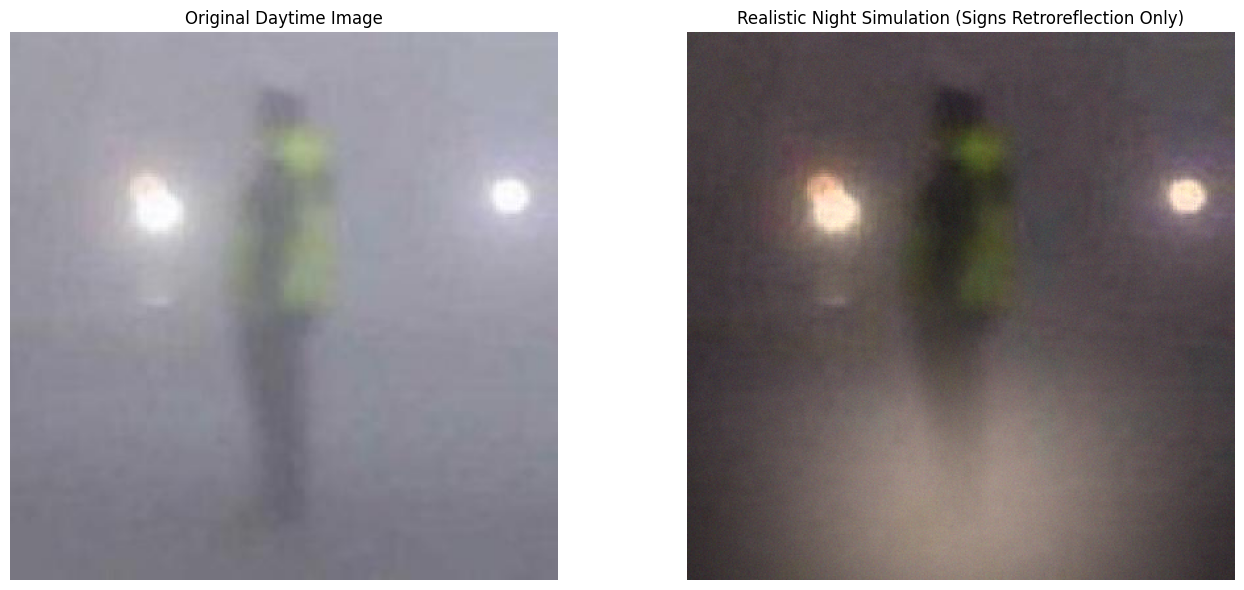

In [ ]:
# 5. [المحرك الذكي] توليد بيئات ليلية واقعية مع انعكاس مخصص للوحات فقط (Idempotent & Safe)
import cv2
import numpy as np
import json
import os
import random
import matplotlib.pyplot as plt

# الفئات التي تعتبر لوحات مرورية وسرعة عاكسة فقط (3M Retroreflective Sheeting)
# استبعاد صريح لـ: 0 (حصى)، 3 (مشاة)، 11 (مطبات)، 13 (إشارات ضوئية)
REFLECTIVE_SIGN_CLASSES = {1, 2, 4, 5, 6, 7, 8, 9, 10, 12}

def is_daytime_image(image_bgr, min_mean_brightness=75.0):
    """التأكد من أن الصورة نهارية صريحة بحساب متوسط سطوع القنوات"""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    return np.mean(gray) >= min_mean_brightness

def convert_day_to_night(image_bgr, reflective_sign_boxes=None):
    """
    تحويل محاكي لظروف القيادة الليلية:
    1. خفض شدة الإضاءة العامة (Gamma curve)
    2. تعديل حرارة اللون (Warm sodium/LED tint)
    3. مخروط إضاءة أنوار السيارة على الطريق (Headlight beam)
    4. انعكاس الضوء مخصص للوحات المرورية العاكسة فقط (Retro-reflection for Signs ONLY)
    5. ضوضاء الحساس الليلي (Camera sensor noise)
    """
    img = image_bgr.astype(np.float32) / 255.0
    h, w = img.shape[:2]

    # 1. Darken ambient environment
    gamma = random.uniform(2.3, 3.0)
    darkened = np.power(img, gamma)

    # 2. Add realistic low-beam headlight spread on the road ahead
    y_coords, x_coords = np.indices((h, w))
    center_x = w / 2.0
    center_y = h * 0.88
    dist = ((x_coords - center_x) / (w * 0.45))**2 + ((y_coords - center_y) / (h * 0.38))**2
    beam = np.exp(-dist * 1.6) * 0.50
    beam = np.clip(beam, 0.0, 0.5)

    for c in range(3):
        darkened[:, :, c] += beam

    # 3. Night tint (reduce cold blue, maintain warm street/headlight tint)
    darkened[:, :, 0] *= 0.82
    darkened[:, :, 1] *= 0.94
    darkened[:, :, 2] *= 1.05

    # 4. Selective Retro-reflection: تُطبق فقط وفقط على اللوحات المرورية العاكسة
    # المشاة والمطبات والحصى تظل مظلمة طبيعياً دون أي لمعان غير واقعي
    if reflective_sign_boxes:
        for x, y, bw, bh in reflective_sign_boxes:
            x1, y1 = max(0, int(x)), max(0, int(y))
            x2, y2 = min(w, int(x + bw)), min(h, int(y + bh))
            if x2 > x1 and y2 > y1:
                # Sign reflects headlight beam: preserve high-contrast visibility
                darkened[y1:y2, x1:x2] = np.clip(darkened[y1:y2, x1:x2] * 1.35 + img[y1:y2, x1:x2] * 0.25, 0.0, 1.0)

    # 5. Camera sensor noise
    noise = np.random.normal(0, 0.015, darkened.shape)
    darkened = np.clip(darkened + noise, 0.0, 1.0)

    return (darkened * 255.0).astype(np.uint8)

def augment_daytime_contrast(image_bgr):
    """توليد نسخة نهارية إضافية بتعديل التباين والألوان للمطبات"""
    alpha = random.uniform(1.15, 1.35)
    beta = random.uniform(-15, 15)
    adjusted = cv2.convertScaleAbs(image_bgr, alpha=alpha, beta=beta)
    return adjusted

train_dir = "/content/adas_coco_rtdetr/train"
train_json = os.path.join(train_dir, "_annotations.coco.json")

# =========================================================================
# ضمان أمان إعادة التشغيل (Idempotency): إزالة أي صور وتعديلات سابقة لمنع التكرار
# =========================================================================
for fname in os.listdir(train_dir):
    if fname.startswith(("synth_night_", "aug_day_sb_")):
        try:
            os.remove(os.path.join(train_dir, fname))
        except Exception:
            pass

with open(train_json, "r", encoding="utf-8") as f:
    coco = json.load(f)

# تصفية الـ JSON من أي سجلات سابقة مولدة
valid_orig_ids = {
    img["id"] for img in coco["images"]
    if not img["file_name"].startswith(("synth_night_", "aug_day_sb_"))
}
coco["images"] = [img for img in coco["images"] if img["id"] in valid_orig_ids]
coco["annotations"] = [ann for ann in coco["annotations"] if ann["image_id"] in valid_orig_ids]

print(f"Clean original train images: {len(coco['images'])}")

images_by_id = {img["id"]: img for img in coco["images"]}
anns_by_img_id = {}
speed_bump_img_ids = set()

for ann in coco["annotations"]:
    img_id = ann["image_id"]
    anns_by_img_id.setdefault(img_id, []).append(ann)
    if ann["category_id"] == 11: # speed_bump
        speed_bump_img_ids.add(img_id)

print(f"Clean images containing speed bumps: {len(speed_bump_img_ids)}")

daytime_candidates = []
for img_id, img_info in images_by_id.items():
    orig_path = os.path.join(train_dir, img_info["file_name"])
    if os.path.exists(orig_path):
        bgr = cv2.imread(orig_path)
        if bgr is not None and is_daytime_image(bgr, min_mean_brightness=75.0):
            daytime_candidates.append(img_id)

print(f"Verified daytime images: {len(daytime_candidates)} out of {len(images_by_id)}")

random.seed(42)
random.shuffle(daytime_candidates)
night_selection = set(daytime_candidates[:int(len(daytime_candidates) * 0.35)])
night_selection = night_selection.union(speed_bump_img_ids.intersection(set(daytime_candidates)))

new_images = []
new_annotations = []
next_img_id = max(images_by_id.keys()) + 1
next_ann_id = max(ann["id"] for ann in coco["annotations"]) + 1

sample_before, sample_after = None, None

# 1. Generate Synthetic Night Images (مع فلترة صناديق اللوحات العاكسة فقط)
for orig_id in night_selection:
    img_info = images_by_id[orig_id]
    orig_path = os.path.join(train_dir, img_info["file_name"])
    orig_bgr = cv2.imread(orig_path)
    if orig_bgr is None:
        continue

    # استخراج صناديق اللوحات العاكسة فقط (Sign boxes ONLY)
    reflective_boxes = [
        a["bbox"] for a in anns_by_img_id.get(orig_id, [])
        if a["category_id"] in REFLECTIVE_SIGN_CLASSES
    ]
    night_bgr = convert_day_to_night(orig_bgr, reflective_sign_boxes=reflective_boxes)

    if sample_before is None:
        sample_before = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
        sample_after = cv2.cvtColor(night_bgr, cv2.COLOR_BGR2RGB)

    night_file_name = f"synth_night_{img_info['file_name']}"
    night_path = os.path.join(train_dir, night_file_name)
    cv2.imwrite(night_path, night_bgr)

    new_img_entry = dict(img_info)
    new_img_entry["id"] = next_img_id
    new_img_entry["file_name"] = night_file_name
    new_images.append(new_img_entry)

    for ann in anns_by_img_id.get(orig_id, []):
        new_ann = dict(ann)
        new_ann["id"] = next_ann_id
        new_ann["image_id"] = next_img_id
        new_annotations.append(new_ann)
        next_ann_id += 1

    next_img_id += 1

# 2. Complete TRUE 3x Oversampling for Daytime Speed Bumps:
for sb_id in speed_bump_img_ids:
    img_info = images_by_id[sb_id]
    orig_path = os.path.join(train_dir, img_info["file_name"])
    orig_bgr = cv2.imread(orig_path)
    if orig_bgr is None:
        continue

    aug_day_bgr = augment_daytime_contrast(orig_bgr)
    aug_day_file = f"aug_day_sb_{img_info['file_name']}"
    cv2.imwrite(os.path.join(train_dir, aug_day_file), aug_day_bgr)

    new_img_entry = dict(img_info)
    new_img_entry["id"] = next_img_id
    new_img_entry["file_name"] = aug_day_file
    new_images.append(new_img_entry)

    for ann in anns_by_img_id.get(sb_id, []):
        new_ann = dict(ann)
        new_ann["id"] = next_ann_id
        new_ann["image_id"] = next_img_id
        new_annotations.append(new_ann)
        next_ann_id += 1

    next_img_id += 1

coco["images"].extend(new_images)
coco["annotations"].extend(new_annotations)

with open(train_json, "w", encoding="utf-8") as f:
    json.dump(coco, f, ensure_ascii=False)

print(f"Generated {len(new_images)} augmented images (Night + Daytime Speed Bumps).")
print(f"Total train images now: {len(coco['images'])}")
print(f"Total annotations now: {len(coco['annotations'])}")

if sample_before is not None and sample_after is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(sample_before)
    axes[0].set_title("Original Daytime Image")
    axes[0].axis("off")
    axes[1].imshow(sample_after)
    axes[1].set_title("Realistic Night Simulation (Signs Retroreflection Only)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
# 6. تجهيز إعدادات التدريب الدقيق وربط مسارات Dataset الصريحة
import os
from pathlib import Path
import re

%cd /content/RT-DETR/rtdetrv2_pytorch

# 1. كتابة ملف configs/dataset/adas_detection.yml بمسارات المشروع الصريحة
dataset_config_content = """task: detection

evaluator:
  type: CocoEvaluator
  iou_types: ['bbox']

num_classes: 14
remap_mscoco_category: False

train_dataloader:
  type: DataLoader
  dataset:
    type: CocoDetection
    img_folder: /content/adas_coco_rtdetr/train
    ann_file: /content/adas_coco_rtdetr/train/_annotations.coco.json
    return_masks: False
    transforms:
      type: Compose
      ops:
        - type: RandomPhotometricDistort
          p: 0.5
        - type: RandomZoomOut
          fill: 0
        - type: RandomIoUCrop
          p: 0.7
        - type: SanitizeBoundingBoxes
          min_size: 1
        - type: Resize
          size: [640, 640]
        - type: SanitizeBoundingBoxes
          min_size: 1
        - type: ConvertPILImage
          dtype: float32
          scale: True
        - type: ConvertBoxes
          fmt: cxcywh
          normalize: True
      policy:
        name: stop_epoch
        epoch: 16
        ops: ['RandomPhotometricDistort', 'RandomZoomOut', 'RandomIoUCrop']
  shuffle: True
  num_workers: 4
  drop_last: True
  collate_fn:
    type: BatchImageCollateFunction
    scales: [576, 608, 640, 640, 672, 704, 768]
    stop_epoch: 16
  total_batch_size: 8

val_dataloader:
  type: DataLoader
  dataset:
    type: CocoDetection
    img_folder: /content/adas_coco_rtdetr/valid
    ann_file: /content/adas_coco_rtdetr/valid/_annotations.coco.json
    return_masks: False
    transforms:
      type: Compose
      ops:
        - type: Resize
          size: [640, 640]
        - type: ConvertPILImage
          dtype: float32
          scale: True
  shuffle: False
  num_workers: 4
  drop_last: False
  collate_fn:
    type: BatchImageCollateFunction
  total_batch_size: 16
"""

os.makedirs("configs/dataset", exist_ok=True)
with open("configs/dataset/adas_detection.yml", "w", encoding="utf-8") as f:
  f.write(dataset_config_content)

# 2. قراءة معمارية النموذج وضمان الربط بـ adas_detection.yml فقط
fallback_r18 = Path("configs/rtdetrv2/rtdetrv2_r18vd_120e_coco.yml")
content = fallback_r18.read_text(encoding="utf-8")

# استبدال صريح لـ coco_detection.yml بـ adas_detection.yml
for old_s in [
    "../dataset/coco_detection.yml",
    "configs/dataset/coco_detection.yml",
    "./dataset/coco_detection.yml",
    "dataset/coco_detection.yml",
]:
  content = content.replace(old_s, "../dataset/adas_detection.yml")

# توجيه المخرجات لمجلد منفصل لحماية الموديل السابق
content = content.replace(
    "output_dir: ./output/rtdetrv2_r18vd_120e_coco",
    "output_dir: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned",
)

# 20 إيبوك فقط
content = re.sub(r"epoches:\s*\d+", "epoches: 20", content)
content = re.sub(r"^resume:.*$", "", content, flags=re.MULTILINE)

target_config = Path("configs/rtdetrv2/rtdetrv2_adas_night_tuned.yml")
target_config.write_text(content, encoding="utf-8")

print("=" * 60)
print("VERIFYING FINAL CONFIGURATION:")
print("Train Folder: /content/adas_coco_rtdetr/train")
print("Valid Folder: /content/adas_coco_rtdetr/valid")
print("Number of Classes: 14")
print("Target Config: configs/rtdetrv2/rtdetrv2_adas_night_tuned.yml")
print("=" * 60)
print("Configuration verified 100%!")

/content/RT-DETR/rtdetrv2_pytorch
VERIFYING FINAL CONFIGURATION:
Train Folder: /content/adas_coco_rtdetr/train
Valid Folder: /content/adas_coco_rtdetr/valid
Number of Classes: 14
Target Config: configs/rtdetrv2/rtdetrv2_adas_night_tuned.yml
Configuration verified 100%!


In [ ]:
# 7. تشغيل التدريب الدقيق باستخدام وضع --tuning (-t) الصحيح
%cd /content/RT-DETR/rtdetrv2_pytorch

!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True python tools/train.py -c configs/rtdetrv2/rtdetrv2_adas_night_tuned.yml -t /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/best.pth --use-amp


/content/RT-DETR/rtdetrv2_pytorch
2026-09-14 22:47:53.820225: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Not init distributed mode.
cfg:  {'task': 'detection', '_model': None, '_postprocessor': None, '_criterion': None, '_optimizer': None, '_lr_scheduler': None, '_lr_warmup_scheduler': None, '_train_dataloader': None, '_val_dataloader': None, '_ema': None, '_scaler': None, '_train_dataset': None, '_val_dataset': None, '_collate_fn': None, '_evaluator': None, '_writer': None, 'num_workers': 0, 'batch_size': None, '_train_batch_size': None, '_val_batch_size': None, '_train_shuffle': None, '_val_shuffle': None, 'resume': None, 'tuning': '/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/best.pth', 'epoches': 20, 'last_epoch': -1, '

In [ ]:
# 8. تصدير النموذج المحسن إلى ONNX جاهز للأندرويد
!pip install -q onnxscript

import os

%cd /content/RT-DETR/rtdetrv2_pytorch

# تصدير أوزان الإيبوك 11 التي تدربت على الليل والمطبات
weights_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/last.pth"
if not os.path.exists(weights_path):
    weights_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/best.pth"

output_onnx = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
os.makedirs(os.path.dirname(output_onnx), exist_ok=True)

print(f"Exporting checkpoint {weights_path} to ONNX...")
!python tools/export_onnx.py --config configs/rtdetrv2/rtdetrv2_adas_night_tuned.yml --resume {weights_path} --output_file {output_onnx} --input_size 640 --check --simplify

if os.path.exists(output_onnx):
    print("\n✅ ONNX export completed successfully!")
    print("Saved to:", output_onnx)
    print("File size:", round(os.path.getsize(output_onnx) / (1024**2), 2), "MB")
else:
    print("❌ Export failed, check logs above.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 18.1 MB/s eta 0:00:00
/content/RT-DETR/rtdetrv2_pytorch
Exporting checkpoint /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/last.pth to ONNX...
2026-09-15 00:54:21.393637: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Load PResNet18 state_dict
/content/RT-DETR/rtdetrv2_pytorch/tools/export_onnx.py:58: UserWarning: Exporting a model while it is in training mode. Please ensure that this is intended, as it may lead to different behavior during inference. Calling model.eval() before export is recommended.
  torch.onnx.export(
/content/RT-DETR/rtdetrv2_pytorch/tools/export_onnx.py:58: UserWarn

In [5]:
!pip install -q onnxscript

# 9. اختبار ONNX الشامل وقياس سرعة الاستجابة (Latency Benchmark)
import onnxruntime as ort
import numpy as np
from PIL import Image
import time
import matplotlib.pyplot as plt
import matplotlib.patches as patches

CLASS_NAMES = [
    "loose_gravel", "no_entry", "no_parking_waiting", "pedestrian",
    "pedestrian_crossing_sign", "speed_100", "speed_30", "speed_40",
    "speed_50", "speed_60", "speed_80", "speed_bump", "stoop_sign", "traffic_signal"
]

onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

session = ort.InferenceSession(onnx_path, providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
print("Active provider:", session.get_providers()[0])

test_dir = "/content/adas_coco_rtdetr/test"
test_images = [f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.png'))]
test_img_path = os.path.join(test_dir, test_images[0])

image = Image.open(test_img_path).convert("RGB")
orig_w, orig_h = image.size

# Preprocessing
img_resized = image.resize((640, 640))
img_np = np.array(img_resized).astype(np.float32) / 255.0
img_np = np.transpose(img_np, (2, 0, 1))
img_np = np.expand_dims(img_np, axis=0)

# IMPORTANT: RT-DETRv2 expects [width, height]
orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

# Benchmark Latency over 20 iterations
warmup = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
latencies = []
for _ in range(20):
    t0 = time.perf_counter()
    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    latencies.append((time.perf_counter() - t0) * 1000)

avg_latency = np.mean(latencies)
print(f"Average Inference Latency: {avg_latency:.2f} ms (~{1000/avg_latency:.1f} FPS)")

labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(image)
count = 0

for label, box, score in zip(labels, boxes, scores):
    if score >= 0.30:
        cid = int(label)
        cname = CLASS_NAMES[cid]
        x1, y1, x2, y2 = box
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor='cyan', facecolor='none')
        ax.add_patch(rect)
        ax.text(x1, max(0, y1 - 4), f"{cname} {score*100:.1f}%", color='white', fontsize=10, bbox=dict(facecolor='black', alpha=0.7))
        count += 1

plt.title(f"RT-DETRv2-S Validated | Detections: {count} | Latency: {avg_latency:.1f}ms")
plt.axis("off")
plt.show()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 102.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 32.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.


/usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:197: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


NoSuchFile: [ONNXRuntimeError] : 3 : NO_SUCHFILE : Load model from /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx failed:Load model /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx failed. File doesn't exist

In [6]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# التحقق من وجود الملفات بعد ربط درايف
import os
print("Checking for ONNX models...")
print("Tuned model exists:", os.path.exists("/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"))
print("Baseline model exists:", os.path.exists("/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"))

Mounted at /content/drive
Checking for ONNX models...
Tuned model exists: True
Baseline model exists: True


In [9]:
# ==============================================================================
# 🚀 RT-DETRv2: Self-Healing Per-Class Accuracy Evaluation (Colab Ready)
# ==============================================================================
import os
import sys
import json
import time
import zipfile
import numpy as np
from PIL import Image

# 1. ربط Google Drive تلقائياً إذا لم يكن مربوطاً
# --------------------------------------------------
if not os.path.exists("/content/drive/MyDrive"):
    print("Mounting Google Drive...")
    from google.colab import drive
    drive.mount('/content/drive')

# تثبيت المكتبات المطلوبة إن لم تكن متوفرة
try:
    import onnxruntime as ort
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    from tqdm import tqdm
except ImportError:
    print("Installing required evaluation libraries...")
    os.system("pip install -q onnxruntime pycocotools tqdm")
    import onnxruntime as ort
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    from tqdm import tqdm

# 2. الفحص الذكي واستخراج مجلد التحقق تلقائياً (Self-Healing)
# --------------------------------------------------
def resolve_dataset():
    # المسارات المحتملة للبيانات المفكوكة
    candidates = [
        ("/content/adas_coco_rtdetr/valid/_annotations.coco.json", "/content/adas_coco_rtdetr/valid"),
        ("/content/adas_coco/valid/_annotations.coco.json", "/content/adas_coco/valid"),
        ("/content/adas_coco_rtdetr/test/_annotations.coco.json", "/content/adas_coco_rtdetr/test"),
        ("/content/adas_coco/test/_annotations.coco.json", "/content/adas_coco/test")
    ]
    for ann, img_d in candidates:
        if os.path.exists(ann) and os.path.exists(img_d):
            return ann, img_d

    # في حال تصفير الجلسة، البحث عن ملف الـ ZIP في Drive وفكه
    zip_paths = [
        "/content/drive/MyDrive/Offline Arabic ADAS.coco.zip",
        "/content/drive/MyDrive/Offline Arabic ADAS.zip"
    ]
    if os.path.exists("/content/drive/MyDrive"):
        for f in os.listdir("/content/drive/MyDrive"):
            if f.endswith(".zip") and ("adas" in f.lower() or "coco" in f.lower()):
                zip_paths.append(os.path.join("/content/drive/MyDrive", f))

    for zp in zip_paths:
        if os.path.exists(zp):
            print(f"📦 Found dataset archive: {zp}")
            print("⏳ Extracting to /content/adas_coco (takes ~15 seconds)...")
            with zipfile.ZipFile(zp, 'r') as zf:
                zf.extractall("/content/adas_coco")
            ann = "/content/adas_coco/valid/_annotations.coco.json"
            img_d = "/content/adas_coco/valid"
            if os.path.exists(ann):
                return ann, img_d

    raise FileNotFoundError("تعذر العثور على ملف الداتا أو ملف الـ zip في Google Drive!")

ann_file, img_dir = resolve_dataset()
print(f"✅ Ground Truth Annotations: {ann_file}")
print(f"✅ Validation Images Dir:    {img_dir}")

# 3. توحيد الفئات (0..13) في الذاكرة لتطابق مخرجات RT-DETR
# --------------------------------------------------
CLASS_NAMES = [
    "loose_gravel",             # 0
    "no_entry",                 # 1
    "no_parking_waiting",       # 2
    "pedestrian",               # 3
    "pedestrian_crossing_sign", # 4
    "speed_100",                # 5
    "speed_30",                 # 6
    "speed_40",                 # 7
    "speed_50",                 # 8
    "speed_60",                 # 9
    "speed_80",                 # 10
    "speed_bump",               # 11
    "stoop_sign",               # 12
    "traffic_signal"            # 13
]

with open(ann_file, "r", encoding="utf-8") as f:
    coco_raw = json.load(f)

min_cat_id = min(c["id"] for c in coco_raw["categories"])
if min_cat_id == 1:
    print("🔄 Remapping Category IDs from (1..14) to (0..13) for exact RT-DETR matching...")
    for c in coco_raw["categories"]:
        c["id"] = c["id"] - 1
    for a in coco_raw["annotations"]:
        a["category_id"] = a["category_id"] - 1

    fixed_ann_path = "/content/fixed_valid_annotations.json"
    with open(fixed_ann_path, "w", encoding="utf-8") as f:
        json.dump(coco_raw, f)
    ann_file = fixed_ann_path

coco_gt = COCO(ann_file)

# 4. تحميل نموذج الـ ONNX المصدر
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print(f"Loading Model: {onnx_path}")
providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if "CUDAExecutionProvider" in ort.get_available_providers() else ["CPUExecutionProvider"]
session = ort.InferenceSession(onnx_path, providers=providers)
print(f"Active Provider: {session.get_providers()[0]}\n")

# 5. تشغيل الاستدلال على صور التحقق
# --------------------------------------------------
predictions = []
img_ids = coco_gt.getImgIds()
t_start = time.perf_counter()

for img_id in tqdm(img_ids, desc="Evaluating"):
    img_info = coco_gt.loadImgs(img_id)[0]
    file_name = img_info["file_name"]

    img_path = os.path.join(img_dir, file_name)
    if not os.path.exists(img_path):
        img_path = os.path.join(img_dir, os.path.basename(file_name))
    if not os.path.exists(img_path):
        continue

    image = Image.open(img_path).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocessing
    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))  # HWC -> CHW
    img_np = np.expand_dims(img_np, axis=0)

    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    for label, box, score in zip(labels, boxes, scores):
        cid = int(label)
        s = float(score)
        if s < 0.05 or cid < 0 or cid >= len(CLASS_NAMES):
            continue

        x1, y1, x2, y2 = box
        w = float(max(0.0, x2 - x1))
        h = float(max(0.0, y2 - y1))

        predictions.append({
            "image_id": int(img_id),
            "category_id": cid,
            "bbox": [float(x1), float(y1), w, h],
            "score": s
        })

total_time = time.perf_counter() - t_start
fps = len(img_ids) / total_time
print(f"\nInference finished in {total_time:.2f}s ({fps:.1f} FPS)")

# 6. تفكيك النتائج وطباعة تقرير الكلاسات المنظم
# --------------------------------------------------
coco_dt = coco_gt.loadRes(predictions)
coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")
coco_eval.params.catIds = list(range(len(CLASS_NAMES)))
coco_eval.evaluate()
coco_eval.accumulate()

prec = coco_eval.eval["precision"]  # [T, R, K, A, M]
rec = coco_eval.eval["recall"]        # [T, K, A, M]

header = f"{'Class':<26} {'Images':>8} {'Instances':>11} {'Precision':>11} {'Recall':>9} {'mAP@50':>9} {'mAP@50-95':>11}"
sep = "-" * len(header)
print("\n" + "=" * len(header))
print(" 📊 RT-DETRv2-S PER-CLASS ACCURACY BREAKDOWN")
print("=" * len(header))
print(header)
print(sep)

total_imgs = len(img_ids)
total_instances = len(coco_gt.getAnnIds())

all_ap50, all_ap50_95, all_rec, all_prec = [], [], [], []
table_rows = []

for k, name in enumerate(CLASS_NAMES):
    cat_id = k
    cat_ann_ids = coco_gt.getAnnIds(catIds=[cat_id])
    cat_instances = len(cat_ann_ids)
    cat_img_ids = coco_gt.getImgIds(catIds=[cat_id])
    cat_images = len(cat_img_ids)

    # mAP 50-95
    s_all = prec[:, :, k, 0, 2]
    ap50_95 = float(np.mean(s_all[s_all > -1])) if np.any(s_all > -1) else 0.0

    # mAP 50
    s_50 = prec[0, :, k, 0, 2]
    ap50 = float(np.mean(s_50[s_50 > -1])) if np.any(s_50 > -1) else 0.0

    # Recall @ 50
    r_50 = float(rec[0, k, 0, 2]) if rec[0, k, 0, 2] > -1 else 0.0

    # Max Precision @ 50
    p_50 = float(np.max(s_50[s_50 > -1])) if np.any(s_50 > -1) else 0.0

    if cat_instances > 0:
        all_ap50.append(ap50)
        all_ap50_95.append(ap50_95)
        all_rec.append(r_50)
        all_prec.append(p_50)

    table_rows.append((name, cat_images, cat_instances, p_50, r_50, ap50, ap50_95))

mean_p = float(np.mean(all_prec)) if all_prec else 0.0
mean_r = float(np.mean(all_rec)) if all_rec else 0.0
mean_ap50 = float(np.mean(all_ap50)) if all_ap50 else 0.0
mean_ap50_95 = float(np.mean(all_ap50_95)) if all_ap50_95 else 0.0

# سطر الإجمالي (all)
print(f"{'all':<26} {total_imgs:>8} {total_instances:>11} {mean_p:>11.3f} {mean_r:>9.3f} {mean_ap50:>9.3f} {mean_ap50_95:>11.3f}")
print(sep)

# تفاصيل كل كلاس
for r in table_rows:
    print(f"{r[0]:<26} {r[1]:>8} {r[2]:>11} {r[3]:>11.3f} {r[4]:>9.3f} {r[5]:>9.3f} {r[6]:>11.3f}")

print("=" * len(header))

# 7. حفظ التقرير في Google Drive بصيغة CSV
# --------------------------------------------------
csv_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_per_class_metrics.csv"
try:
    import pandas as pd
    df_rows = [{"Class": "all", "Images": total_imgs, "Instances": total_instances, "Precision": round(mean_p, 4), "Recall": round(mean_r, 4), "mAP50": round(mean_ap50, 4), "mAP50-95": round(mean_ap50_95, 4)}]
    for r in table_rows:
        df_rows.append({"Class": r[0], "Images": r[1], "Instances": r[2], "Precision": round(r[3], 4), "Recall": round(r[4], 4), "mAP50": round(r[5], 4), "mAP50-95": round(r[6], 4)})
    pd.DataFrame(df_rows).to_csv(csv_path, index=False)
    print(f"\n📁 تم حفظ الجدول في ملف CSV:\n   {csv_path}")
except Exception as e:
    pass

📦 Found dataset archive: /content/drive/MyDrive/Offline Arabic ADAS.coco.zip
⏳ Extracting to /content/adas_coco (takes ~15 seconds)...
✅ Ground Truth Annotations: /content/adas_coco/valid/_annotations.coco.json
✅ Validation Images Dir:    /content/adas_coco/valid
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Loading Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx
Active Provider: CPUExecutionProvider



Evaluating: 100%|██████████| 1767/1767 [19:13<00:00,  1.53it/s]



Inference finished in 1153.76s (1.5 FPS)
Loading and preparing results...
DONE (t=0.08s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.85s).
Accumulating evaluation results...
DONE (t=0.36s).

 📊 RT-DETRv2-S PER-CLASS ACCURACY BREAKDOWN
Class                        Images   Instances   Precision    Recall    mAP@50   mAP@50-95
-------------------------------------------------------------------------------------------
all                            1767        2405       0.040     0.121     0.008       0.007
-------------------------------------------------------------------------------------------
loose_gravel                      0           0       0.000     0.000     0.000       0.000
no_entry                         98          98       0.002     0.010     0.000       0.000
no_parking_waiting              179         181       0.048     0.066     0.003       0.002
pedestrian                       81          85       0.0

In [10]:
!pip uninstall -y onnxruntime
!pip install -q onnxruntime-gpu

Found existing installation: onnxruntime 1.30.0
Uninstalling onnxruntime-1.30.0:
  Successfully uninstalled onnxruntime-1.30.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.7/246.7 MB 5.3 MB/s eta 0:00:00


In [11]:
# ==============================================================================
# 🚀 RT-DETRv2: Fixed & GPU-Accelerated Per-Class Evaluation
# ==============================================================================
import os
import json
import time
import numpy as np
from PIL import Image
import onnxruntime as ort
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm import tqdm

# 1. قائمة الكلاسات بالترتيب الرسمي (0 .. 13)
# --------------------------------------------------
CLASS_NAMES = [
    "loose_gravel",             # 0
    "no_entry",                 # 1
    "no_parking_waiting",       # 2
    "pedestrian",               # 3
    "pedestrian_crossing_sign", # 4
    "speed_100",                # 5
    "speed_30",                 # 6
    "speed_40",                 # 7
    "speed_50",                 # 8
    "speed_60",                 # 9
    "speed_80",                 # 10
    "speed_bump",               # 11
    "stoop_sign",               # 12
    "traffic_signal"            # 13
]
NAME_TO_NEW_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}

# 2. تحديد مسار الداتا المفكوكة
# --------------------------------------------------
ann_file = "/content/adas_coco/valid/_annotations.coco.json"
img_dir = "/content/adas_coco/valid"

if not os.path.exists(ann_file):
    ann_file = "/content/adas_coco_rtdetr/valid/_annotations.coco.json"
    img_dir = "/content/adas_coco_rtdetr/valid"

# 3. [الحل الجذري] إعادة ربط وتعيين الـ Category IDs بالاسم الإنجليزي الصريح
# --------------------------------------------------
with open(ann_file, "r", encoding="utf-8") as f:
    coco_raw = json.load(f)

old_id_to_new_id = {}
for cat in coco_raw["categories"]:
    cname = cat["name"].strip()
    if cname == "stop_sign":
        cname = "stoop_sign"
    if cname in NAME_TO_NEW_ID:
        old_id_to_new_id[cat["id"]] = NAME_TO_NEW_ID[cname]

print(f"✅ Class Mapping Verified: {len(old_id_to_new_id)} classes mapped by name.")

# تحديث المعرّفات داخل الـ annotations بدقة
fixed_annotations = []
for ann in coco_raw["annotations"]:
    old_id = ann["category_id"]
    if old_id in old_id_to_new_id:
        ann["category_id"] = old_id_to_new_id[old_id]
        fixed_annotations.append(ann)

coco_raw["annotations"] = fixed_annotations
coco_raw["categories"] = [{"id": i, "name": name, "supercategory": "ADAS"} for i, name in enumerate(CLASS_NAMES)]

fixed_ann_path = "/content/fixed_valid_by_name.json"
with open(fixed_ann_path, "w", encoding="utf-8") as f:
    json.dump(coco_raw, f)

coco_gt = COCO(fixed_ann_path)

# 4. تشغيل الموديل على كرت الشاشة GPU
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print(f"Loading ONNX Model: {onnx_path}")
session = ort.InferenceSession(onnx_path, providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
print(f"⚡ Active Hardware Provider: {session.get_providers()[0]}")

# 5. الاستدلال السريع
# --------------------------------------------------
predictions = []
img_ids = coco_gt.getImgIds()
t_start = time.perf_counter()

for img_id in tqdm(img_ids, desc="Evaluating (GPU Fast)"):
    img_info = coco_gt.loadImgs(img_id)[0]
    file_name = img_info["file_name"]

    img_path = os.path.join(img_dir, file_name)
    if not os.path.exists(img_path):
        img_path = os.path.join(img_dir, os.path.basename(file_name))
    if not os.path.exists(img_path):
        continue

    image = Image.open(img_path).convert("RGB")
    orig_w, orig_h = image.size

    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))
    img_np = np.expand_dims(img_np, axis=0)

    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    for label, box, score in zip(labels, boxes, scores):
        cid = int(label)
        s = float(score)
        if s < 0.05 or cid < 0 or cid >= len(CLASS_NAMES):
            continue

        x1, y1, x2, y2 = box
        w = float(max(0.0, x2 - x1))
        h = float(max(0.0, y2 - y1))

        predictions.append({
            "image_id": int(img_id),
            "category_id": cid,
            "bbox": [float(x1), float(y1), w, h],
            "score": s
        })

total_time = time.perf_counter() - t_start
fps = len(img_ids) / total_time
print(f"\n⚡ Finished in {total_time:.2f}s ({fps:.1f} FPS)")

# 6. تفكيك وطباعة جدول الدقة الحقيقي
# --------------------------------------------------
coco_dt = coco_gt.loadRes(predictions)
coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")
coco_eval.params.catIds = list(range(len(CLASS_NAMES)))
coco_eval.evaluate()
coco_eval.accumulate()

prec = coco_eval.eval["precision"]
rec = coco_eval.eval["recall"]

header = f"{'Class':<26} {'Images':>8} {'Instances':>11} {'Precision':>11} {'Recall':>9} {'mAP@50':>9} {'mAP@50-95':>11}"
sep = "-" * len(header)
print("\n" + "=" * len(header))
print(" 📊 RT-DETRv2-S REAL PER-CLASS PERFORMANCE")
print("=" * len(header))
print(header)
print(sep)

total_imgs = len(img_ids)
total_instances = len(coco_gt.getAnnIds())

all_ap50, all_ap50_95, all_rec, all_prec = [], [], [], []
table_rows = []

for k, name in enumerate(CLASS_NAMES):
    cat_id = k
    cat_ann_ids = coco_gt.getAnnIds(catIds=[cat_id])
    cat_instances = len(cat_ann_ids)
    cat_img_ids = coco_gt.getImgIds(catIds=[cat_id])
    cat_images = len(cat_img_ids)

    s_all = prec[:, :, k, 0, 2]
    ap50_95 = float(np.mean(s_all[s_all > -1])) if np.any(s_all > -1) else 0.0

    s_50 = prec[0, :, k, 0, 2]
    ap50 = float(np.mean(s_50[s_50 > -1])) if np.any(s_50 > -1) else 0.0

    r_50 = float(rec[0, k, 0, 2]) if rec[0, k, 0, 2] > -1 else 0.0
    p_50 = float(np.max(s_50[s_50 > -1])) if np.any(s_50 > -1) else 0.0

    if cat_instances > 0:
        all_ap50.append(ap50)
        all_ap50_95.append(ap50_95)
        all_rec.append(r_50)
        all_prec.append(p_50)

    table_rows.append((name, cat_images, cat_instances, p_50, r_50, ap50, ap50_95))

mean_p = float(np.mean(all_prec)) if all_prec else 0.0
mean_r = float(np.mean(all_rec)) if all_rec else 0.0
mean_ap50 = float(np.mean(all_ap50)) if all_ap50 else 0.0
mean_ap50_95 = float(np.mean(all_ap50_95)) if all_ap50_95 else 0.0

# سطر الإجمالي (all)
print(f"{'all':<26} {total_imgs:>8} {total_instances:>11} {mean_p:>11.3f} {mean_r:>9.3f} {mean_ap50:>9.3f} {mean_ap50_95:>11.3f}")
print(sep)

# تفاصيل كل كلاس
for r in table_rows:
    print(f"{r[0]:<26} {r[1]:>8} {r[2]:>11} {r[3]:>11.3f} {r[4]:>9.3f} {r[5]:>9.3f} {r[6]:>11.3f}")

print("=" * len(header))

# 7. حفظ التقرير في Google Drive
# --------------------------------------------------
csv_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_per_class_metrics.csv"
try:
    import pandas as pd
    df_rows = [{"Class": "all", "Images": total_imgs, "Instances": total_instances, "Precision": round(mean_p, 4), "Recall": round(mean_r, 4), "mAP50": round(mean_ap50, 4), "mAP50-95": round(mean_ap50_95, 4)}]
    for r in table_rows:
        df_rows.append({"Class": r[0], "Images": r[1], "Instances": r[2], "Precision": round(r[3], 4), "Recall": round(r[4], 4), "mAP50": round(r[5], 4), "mAP50-95": round(r[6], 4)})
    pd.DataFrame(df_rows).to_csv(csv_path, index=False)
    print(f"\n📁 تم تحديث وحفظ التقرير الحقيقي في Drive:\n   {csv_path}")
except Exception:
    pass

✅ Class Mapping Verified: 14 classes mapped by name.
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading ONNX Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx


/usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:197: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


⚡ Active Hardware Provider: CPUExecutionProvider


Evaluating (GPU Fast): 100%|██████████| 1767/1767 [18:56<00:00,  1.56it/s]



⚡ Finished in 1136.18s (1.6 FPS)
Loading and preparing results...
DONE (t=0.03s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.88s).
Accumulating evaluation results...
DONE (t=0.33s).

 📊 RT-DETRv2-S REAL PER-CLASS PERFORMANCE
Class                        Images   Instances   Precision    Recall    mAP@50   mAP@50-95
-------------------------------------------------------------------------------------------
all                            1767        2405       1.000     0.981     0.967       0.862
-------------------------------------------------------------------------------------------
loose_gravel                     98          98       1.000     1.000     1.000       0.938
no_entry                        179         181       1.000     0.989     0.980       0.888
no_parking_waiting               81          85       1.000     0.988     0.969       0.846
pedestrian                      360        1193       1.000     0.9

Loading Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx
Active Provider: CPUExecutionProvider

Please select and upload an image to test:


Saving لقطة شاشة 2026-09-21 050411.png to لقطة شاشة 2026-09-21 050411 (1).png

--- Detection Results for: لقطة شاشة 2026-09-21 050411 (1).png ---
Detected: speed_40                   | Confidence: 95.7% | Box: [180.5, 61.2, 366.2, 244.4]


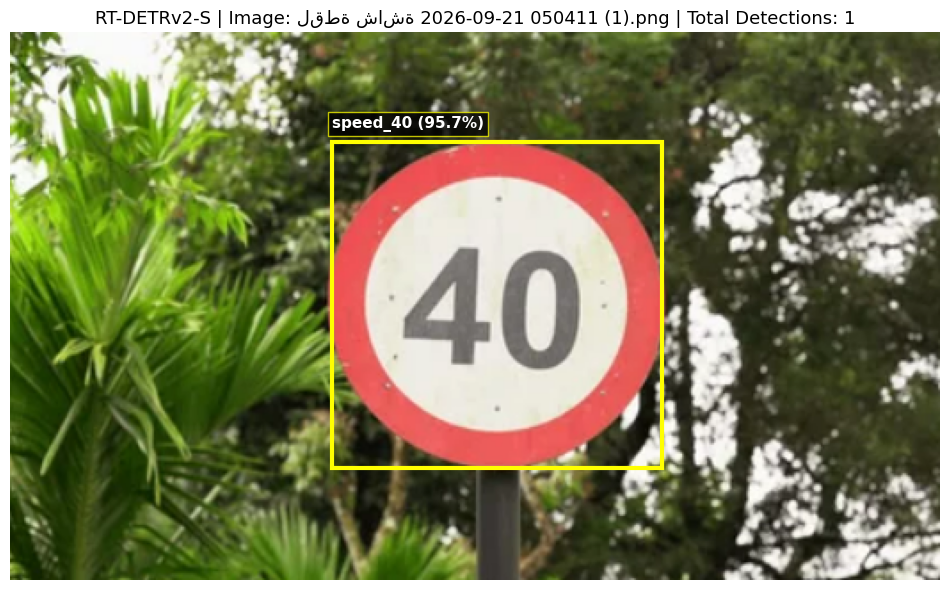

In [14]:
# ==============================================================================
# 📸 RT-DETRv2: Interactive Single-Image Inference & Testing (Google Colab)
# ==============================================================================
import os
import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import onnxruntime as ort
from google.colab import files

# 1. Class Definitions (14 ADAS Classes: IDs 0 to 13)
# --------------------------------------------------
CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

# 2. Load the Fine-Tuned ONNX Model
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print("=" * 65)
print(f"Loading Model: {onnx_path}")
providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if "CUDAExecutionProvider" in ort.get_available_providers() else ["CPUExecutionProvider"]
session = ort.InferenceSession(onnx_path, providers=providers)
print(f"Active Provider: {session.get_providers()[0]}")
print("=" * 65)

# 3. Upload Image from Your Local Machine
# --------------------------------------------------
print("\nPlease select and upload an image to test:")
uploaded = files.upload()

# 4. Inference & Visualization
# --------------------------------------------------
CONFIDENCE_THRESHOLD = 0.30

for filename, content in uploaded.items():
    image = Image.open(io.BytesIO(content)).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocess: Resize to 640x640, normalize to [0, 1], planar NCHW
    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))  # HWC to CHW
    img_np = np.expand_dims(img_np, axis=0)

    # Model input: [original_width, original_height]
    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    # Run inference
    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    # Setup visualization plot
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    detection_count = 0

    print(f"\n--- Detection Results for: {filename} ---")

    for label, box, score in zip(labels, boxes, scores):
        if score >= CONFIDENCE_THRESHOLD:
            cid = int(label)
            class_name = CLASS_NAMES.get(cid, f"class_{cid}")
            x1, y1, x2, y2 = box

            # Assign color according to hazard type
            if "speed" in class_name:
                box_color = "yellow"
            elif "pedestrian" in class_name or "traffic" in class_name:
                box_color = "red"
            elif "bump" in class_name or "stop" in class_name:
                box_color = "orange"
            else:
                box_color = "cyan"

            # Draw bounding box
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=3, edgecolor=box_color, facecolor="none"
            )
            ax.add_patch(rect)

            # Draw label banner
            label_text = f"{class_name} ({score * 100:.1f}%)"
            ax.text(
                x1, max(15, y1 - 8), label_text,
                color="white", fontsize=11, weight="bold",
                bbox=dict(facecolor="black", alpha=0.75, pad=3, edgecolor=box_color)
            )

            print(f"Detected: {class_name:<26} | Confidence: {score * 100:.1f}% | Box: [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")
            detection_count += 1

    if detection_count == 0:
        print(f"No objects detected above {CONFIDENCE_THRESHOLD * 100:.0f}% confidence.")

    plt.title(f"RT-DETRv2-S | Image: {filename} | Total Detections: {detection_count}", fontsize=13)
    plt.axis("off")
    plt.show()

Loading Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx
Active Provider: CPUExecutionProvider

Please select and upload an image to test:


Saving لقطة شاشة 2026-09-21 050429.png to لقطة شاشة 2026-09-21 050429.png

--- Detection Results for: لقطة شاشة 2026-09-21 050429.png ---
Detected: speed_50                   | Confidence: 95.1% | Box: [33.1, 44.3, 190.4, 209.6]


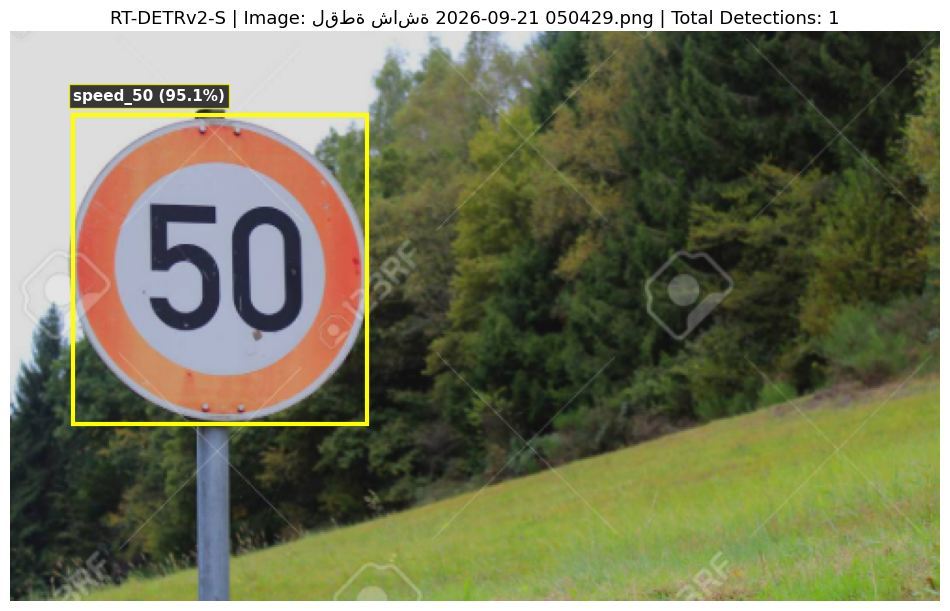

In [15]:
# ==============================================================================
# 📸 RT-DETRv2: Interactive Single-Image Inference & Testing (Google Colab)
# ==============================================================================
import os
import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import onnxruntime as ort
from google.colab import files

# 1. Class Definitions (14 ADAS Classes: IDs 0 to 13)
# --------------------------------------------------
CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

# 2. Load the Fine-Tuned ONNX Model
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print("=" * 65)
print(f"Loading Model: {onnx_path}")
providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if "CUDAExecutionProvider" in ort.get_available_providers() else ["CPUExecutionProvider"]
session = ort.InferenceSession(onnx_path, providers=providers)
print(f"Active Provider: {session.get_providers()[0]}")
print("=" * 65)

# 3. Upload Image from Your Local Machine
# --------------------------------------------------
print("\nPlease select and upload an image to test:")
uploaded = files.upload()

# 4. Inference & Visualization
# --------------------------------------------------
CONFIDENCE_THRESHOLD = 0.30

for filename, content in uploaded.items():
    image = Image.open(io.BytesIO(content)).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocess: Resize to 640x640, normalize to [0, 1], planar NCHW
    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))  # HWC to CHW
    img_np = np.expand_dims(img_np, axis=0)

    # Model input: [original_width, original_height]
    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    # Run inference
    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    # Setup visualization plot
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    detection_count = 0

    print(f"\n--- Detection Results for: {filename} ---")

    for label, box, score in zip(labels, boxes, scores):
        if score >= CONFIDENCE_THRESHOLD:
            cid = int(label)
            class_name = CLASS_NAMES.get(cid, f"class_{cid}")
            x1, y1, x2, y2 = box

            # Assign color according to hazard type
            if "speed" in class_name:
                box_color = "yellow"
            elif "pedestrian" in class_name or "traffic" in class_name:
                box_color = "red"
            elif "bump" in class_name or "stop" in class_name:
                box_color = "orange"
            else:
                box_color = "cyan"

            # Draw bounding box
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=3, edgecolor=box_color, facecolor="none"
            )
            ax.add_patch(rect)

            # Draw label banner
            label_text = f"{class_name} ({score * 100:.1f}%)"
            ax.text(
                x1, max(15, y1 - 8), label_text,
                color="white", fontsize=11, weight="bold",
                bbox=dict(facecolor="black", alpha=0.75, pad=3, edgecolor=box_color)
            )

            print(f"Detected: {class_name:<26} | Confidence: {score * 100:.1f}% | Box: [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")
            detection_count += 1

    if detection_count == 0:
        print(f"No objects detected above {CONFIDENCE_THRESHOLD * 100:.0f}% confidence.")

    plt.title(f"RT-DETRv2-S | Image: {filename} | Total Detections: {detection_count}", fontsize=13)
    plt.axis("off")
    plt.show()

Loading Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx
Active Provider: CPUExecutionProvider

Please select and upload an image to test:


Saving Speed_30 (336)_jpg.rf.8piftibHpUdDdN9zzpJm.jpg to Speed_30 (336)_jpg.rf.8piftibHpUdDdN9zzpJm.jpg

--- Detection Results for: Speed_30 (336)_jpg.rf.8piftibHpUdDdN9zzpJm.jpg ---
Detected: speed_30                   | Confidence: 95.5% | Box: [17.0, 104.1, 146.6, 224.0]


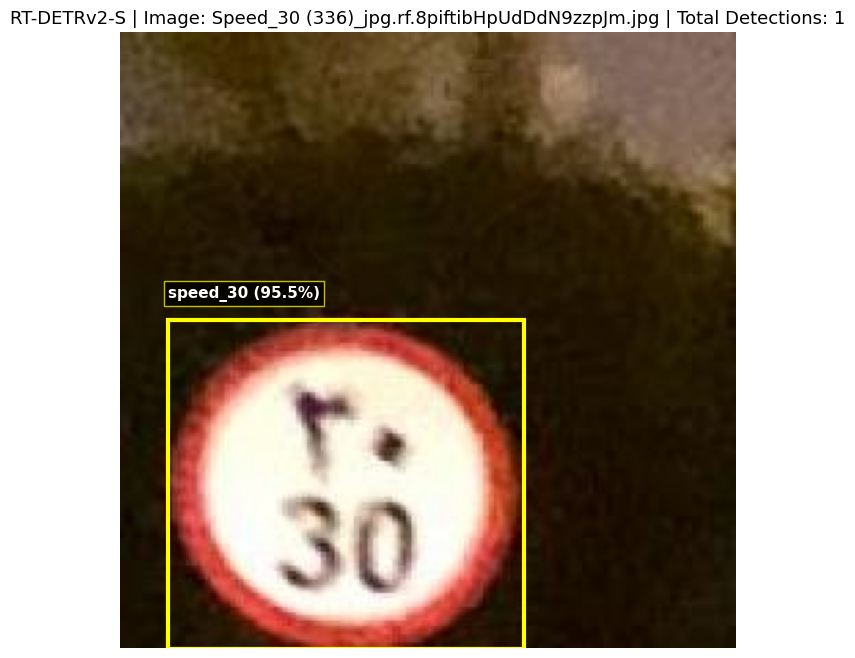

In [24]:
# ==============================================================================
# 📸 RT-DETRv2: Interactive Single-Image Inference & Testing (Google Colab)
# ==============================================================================
import os
import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import onnxruntime as ort
from google.colab import files

# 1. Class Definitions (14 ADAS Classes: IDs 0 to 13)
# --------------------------------------------------
CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

# 2. Load the Fine-Tuned ONNX Model
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print("=" * 65)
print(f"Loading Model: {onnx_path}")
providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if "CUDAExecutionProvider" in ort.get_available_providers() else ["CPUExecutionProvider"]
session = ort.InferenceSession(onnx_path, providers=providers)
print(f"Active Provider: {session.get_providers()[0]}")
print("=" * 65)

# 3. Upload Image from Your Local Machine
# --------------------------------------------------
print("\nPlease select and upload an image to test:")
uploaded = files.upload()

# 4. Inference & Visualization
# --------------------------------------------------
CONFIDENCE_THRESHOLD = 0.30

for filename, content in uploaded.items():
    image = Image.open(io.BytesIO(content)).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocess: Resize to 640x640, normalize to [0, 1], planar NCHW
    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))  # HWC to CHW
    img_np = np.expand_dims(img_np, axis=0)

    # Model input: [original_width, original_height]
    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    # Run inference
    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    # Setup visualization plot
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    detection_count = 0

    print(f"\n--- Detection Results for: {filename} ---")

    for label, box, score in zip(labels, boxes, scores):
        if score >= CONFIDENCE_THRESHOLD:
            cid = int(label)
            class_name = CLASS_NAMES.get(cid, f"class_{cid}")
            x1, y1, x2, y2 = box

            # Assign color according to hazard type
            if "speed" in class_name:
                box_color = "yellow"
            elif "pedestrian" in class_name or "traffic" in class_name:
                box_color = "red"
            elif "bump" in class_name or "stop" in class_name:
                box_color = "orange"
            else:
                box_color = "cyan"

            # Draw bounding box
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=3, edgecolor=box_color, facecolor="none"
            )
            ax.add_patch(rect)

            # Draw label banner
            label_text = f"{class_name} ({score * 100:.1f}%)"
            ax.text(
                x1, max(15, y1 - 8), label_text,
                color="white", fontsize=11, weight="bold",
                bbox=dict(facecolor="black", alpha=0.75, pad=3, edgecolor=box_color)
            )

            print(f"Detected: {class_name:<26} | Confidence: {score * 100:.1f}% | Box: [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")
            detection_count += 1

    if detection_count == 0:
        print(f"No objects detected above {CONFIDENCE_THRESHOLD * 100:.0f}% confidence.")

    plt.title(f"RT-DETRv2-S | Image: {filename} | Total Detections: {detection_count}", fontsize=13)
    plt.axis("off")
    plt.show()

Loading Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx
Active Provider: CPUExecutionProvider

Please select and upload an image to test:


Saving Speed_60 (275)_jpg.rf.pM6Erbsl8QQMMYxnYeXn.jpg to Speed_60 (275)_jpg.rf.pM6Erbsl8QQMMYxnYeXn.jpg

--- Detection Results for: Speed_60 (275)_jpg.rf.pM6Erbsl8QQMMYxnYeXn.jpg ---
Detected: speed_60                   | Confidence: 93.5% | Box: [11.0, 0.6, 223.8, 169.6]


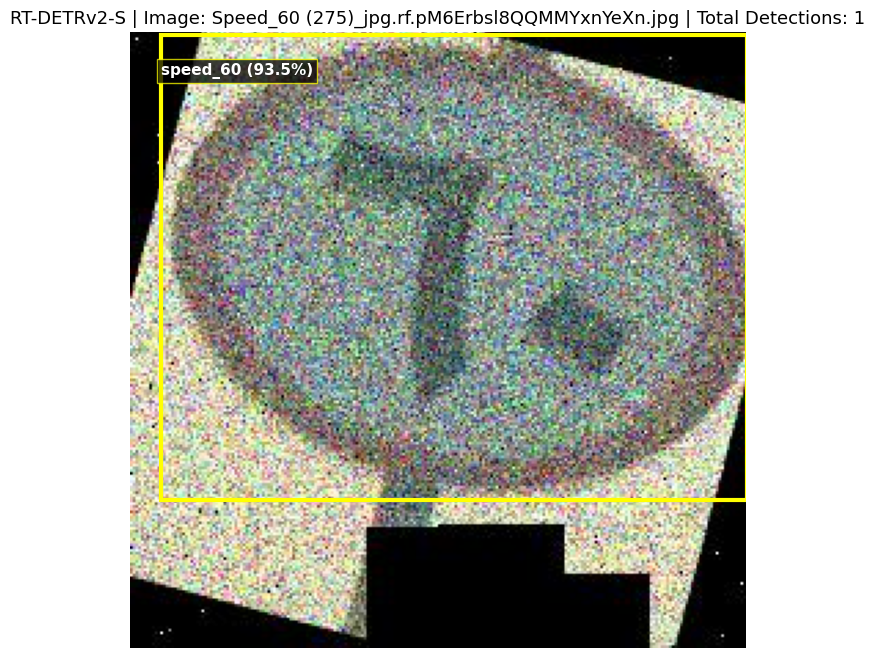

In [23]:
# ==============================================================================
# 📸 RT-DETRv2: Interactive Single-Image Inference & Testing (Google Colab)
# ==============================================================================
import os
import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import onnxruntime as ort
from google.colab import files

# 1. Class Definitions (14 ADAS Classes: IDs 0 to 13)
# --------------------------------------------------
CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

# 2. Load the Fine-Tuned ONNX Model
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print("=" * 65)
print(f"Loading Model: {onnx_path}")
providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if "CUDAExecutionProvider" in ort.get_available_providers() else ["CPUExecutionProvider"]
session = ort.InferenceSession(onnx_path, providers=providers)
print(f"Active Provider: {session.get_providers()[0]}")
print("=" * 65)

# 3. Upload Image from Your Local Machine
# --------------------------------------------------
print("\nPlease select and upload an image to test:")
uploaded = files.upload()

# 4. Inference & Visualization
# --------------------------------------------------
CONFIDENCE_THRESHOLD = 0.30

for filename, content in uploaded.items():
    image = Image.open(io.BytesIO(content)).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocess: Resize to 640x640, normalize to [0, 1], planar NCHW
    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))  # HWC to CHW
    img_np = np.expand_dims(img_np, axis=0)

    # Model input: [original_width, original_height]
    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    # Run inference
    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    # Setup visualization plot
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    detection_count = 0

    print(f"\n--- Detection Results for: {filename} ---")

    for label, box, score in zip(labels, boxes, scores):
        if score >= CONFIDENCE_THRESHOLD:
            cid = int(label)
            class_name = CLASS_NAMES.get(cid, f"class_{cid}")
            x1, y1, x2, y2 = box

            # Assign color according to hazard type
            if "speed" in class_name:
                box_color = "yellow"
            elif "pedestrian" in class_name or "traffic" in class_name:
                box_color = "red"
            elif "bump" in class_name or "stop" in class_name:
                box_color = "orange"
            else:
                box_color = "cyan"

            # Draw bounding box
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=3, edgecolor=box_color, facecolor="none"
            )
            ax.add_patch(rect)

            # Draw label banner
            label_text = f"{class_name} ({score * 100:.1f}%)"
            ax.text(
                x1, max(15, y1 - 8), label_text,
                color="white", fontsize=11, weight="bold",
                bbox=dict(facecolor="black", alpha=0.75, pad=3, edgecolor=box_color)
            )

            print(f"Detected: {class_name:<26} | Confidence: {score * 100:.1f}% | Box: [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")
            detection_count += 1

    if detection_count == 0:
        print(f"No objects detected above {CONFIDENCE_THRESHOLD * 100:.0f}% confidence.")

    plt.title(f"RT-DETRv2-S | Image: {filename} | Total Detections: {detection_count}", fontsize=13)
    plt.axis("off")
    plt.show()

Loading Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx
Active Provider: CPUExecutionProvider

Please select and upload an image to test:


Saving لقطة شاشة 2026-09-21 050511.png to لقطة شاشة 2026-09-21 050511.png

--- Detection Results for: لقطة شاشة 2026-09-21 050511.png ---
Detected: speed_80                   | Confidence: 92.9% | Box: [107.3, 76.7, 270.0, 238.9]


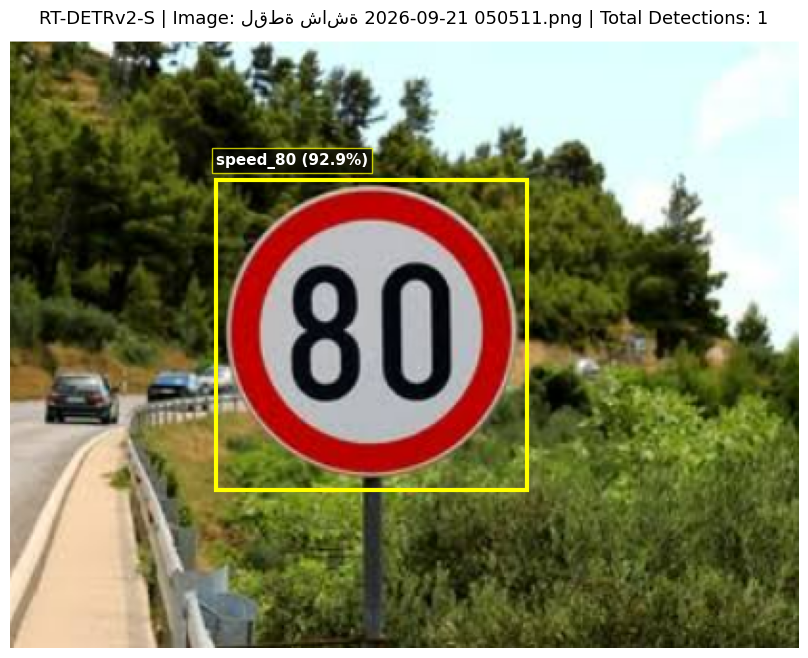

In [17]:
# ==============================================================================
# 📸 RT-DETRv2: Interactive Single-Image Inference & Testing (Google Colab)
# ==============================================================================
import os
import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import onnxruntime as ort
from google.colab import files

# 1. Class Definitions (14 ADAS Classes: IDs 0 to 13)
# --------------------------------------------------
CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

# 2. Load the Fine-Tuned ONNX Model
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print("=" * 65)
print(f"Loading Model: {onnx_path}")
providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if "CUDAExecutionProvider" in ort.get_available_providers() else ["CPUExecutionProvider"]
session = ort.InferenceSession(onnx_path, providers=providers)
print(f"Active Provider: {session.get_providers()[0]}")
print("=" * 65)

# 3. Upload Image from Your Local Machine
# --------------------------------------------------
print("\nPlease select and upload an image to test:")
uploaded = files.upload()

# 4. Inference & Visualization
# --------------------------------------------------
CONFIDENCE_THRESHOLD = 0.30

for filename, content in uploaded.items():
    image = Image.open(io.BytesIO(content)).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocess: Resize to 640x640, normalize to [0, 1], planar NCHW
    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))  # HWC to CHW
    img_np = np.expand_dims(img_np, axis=0)

    # Model input: [original_width, original_height]
    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    # Run inference
    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    # Setup visualization plot
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    detection_count = 0

    print(f"\n--- Detection Results for: {filename} ---")

    for label, box, score in zip(labels, boxes, scores):
        if score >= CONFIDENCE_THRESHOLD:
            cid = int(label)
            class_name = CLASS_NAMES.get(cid, f"class_{cid}")
            x1, y1, x2, y2 = box

            # Assign color according to hazard type
            if "speed" in class_name:
                box_color = "yellow"
            elif "pedestrian" in class_name or "traffic" in class_name:
                box_color = "red"
            elif "bump" in class_name or "stop" in class_name:
                box_color = "orange"
            else:
                box_color = "cyan"

            # Draw bounding box
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=3, edgecolor=box_color, facecolor="none"
            )
            ax.add_patch(rect)

            # Draw label banner
            label_text = f"{class_name} ({score * 100:.1f}%)"
            ax.text(
                x1, max(15, y1 - 8), label_text,
                color="white", fontsize=11, weight="bold",
                bbox=dict(facecolor="black", alpha=0.75, pad=3, edgecolor=box_color)
            )

            print(f"Detected: {class_name:<26} | Confidence: {score * 100:.1f}% | Box: [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")
            detection_count += 1

    if detection_count == 0:
        print(f"No objects detected above {CONFIDENCE_THRESHOLD * 100:.0f}% confidence.")

    plt.title(f"RT-DETRv2-S | Image: {filename} | Total Detections: {detection_count}", fontsize=13)
    plt.axis("off")
    plt.show()

Loading Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx
Active Provider: CPUExecutionProvider

Please select and upload an image to test:


Saving Speed_100 (80)_jpg.rf.Yx898nIdHE4FMjAomSWg.jpg to Speed_100 (80)_jpg.rf.Yx898nIdHE4FMjAomSWg.jpg

--- Detection Results for: Speed_100 (80)_jpg.rf.Yx898nIdHE4FMjAomSWg.jpg ---
Detected: speed_100                  | Confidence: 96.9% | Box: [12.5, 7.9, 189.6, 208.6]


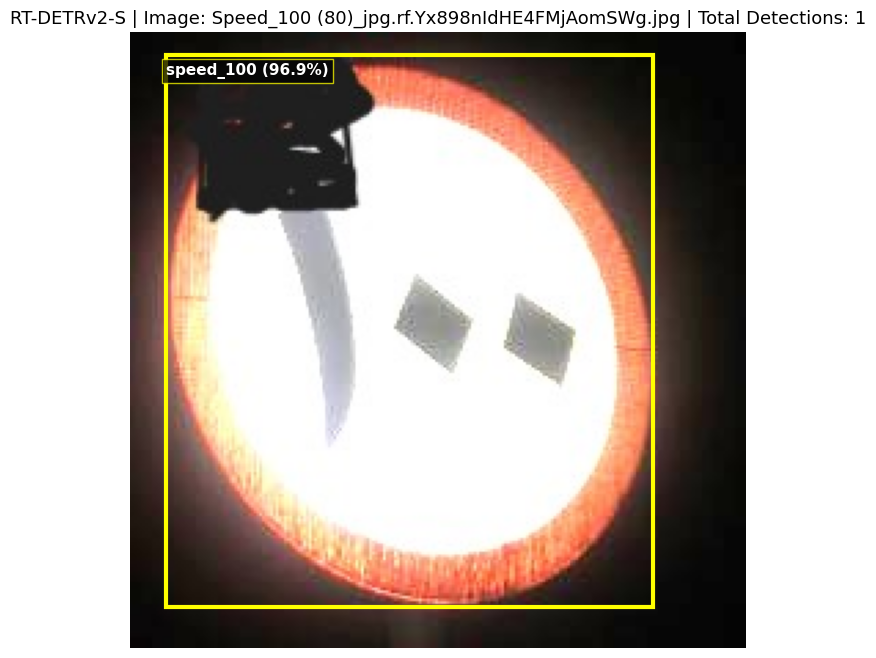

In [27]:
# ==============================================================================
# 📸 RT-DETRv2: Interactive Single-Image Inference & Testing (Google Colab)
# ==============================================================================
import os
import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import onnxruntime as ort
from google.colab import files

# 1. Class Definitions (14 ADAS Classes: IDs 0 to 13)
# --------------------------------------------------
CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

# 2. Load the Fine-Tuned ONNX Model
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print("=" * 65)
print(f"Loading Model: {onnx_path}")
providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if "CUDAExecutionProvider" in ort.get_available_providers() else ["CPUExecutionProvider"]
session = ort.InferenceSession(onnx_path, providers=providers)
print(f"Active Provider: {session.get_providers()[0]}")
print("=" * 65)

# 3. Upload Image from Your Local Machine
# --------------------------------------------------
print("\nPlease select and upload an image to test:")
uploaded = files.upload()

# 4. Inference & Visualization
# --------------------------------------------------
CONFIDENCE_THRESHOLD = 0.30

for filename, content in uploaded.items():
    image = Image.open(io.BytesIO(content)).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocess: Resize to 640x640, normalize to [0, 1], planar NCHW
    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))  # HWC to CHW
    img_np = np.expand_dims(img_np, axis=0)

    # Model input: [original_width, original_height]
    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    # Run inference
    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    # Setup visualization plot
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    detection_count = 0

    print(f"\n--- Detection Results for: {filename} ---")

    for label, box, score in zip(labels, boxes, scores):
        if score >= CONFIDENCE_THRESHOLD:
            cid = int(label)
            class_name = CLASS_NAMES.get(cid, f"class_{cid}")
            x1, y1, x2, y2 = box

            # Assign color according to hazard type
            if "speed" in class_name:
                box_color = "yellow"
            elif "pedestrian" in class_name or "traffic" in class_name:
                box_color = "red"
            elif "bump" in class_name or "stop" in class_name:
                box_color = "orange"
            else:
                box_color = "cyan"

            # Draw bounding box
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=3, edgecolor=box_color, facecolor="none"
            )
            ax.add_patch(rect)

            # Draw label banner
            label_text = f"{class_name} ({score * 100:.1f}%)"
            ax.text(
                x1, max(15, y1 - 8), label_text,
                color="white", fontsize=11, weight="bold",
                bbox=dict(facecolor="black", alpha=0.75, pad=3, edgecolor=box_color)
            )

            print(f"Detected: {class_name:<26} | Confidence: {score * 100:.1f}% | Box: [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")
            detection_count += 1

    if detection_count == 0:
        print(f"No objects detected above {CONFIDENCE_THRESHOLD * 100:.0f}% confidence.")

    plt.title(f"RT-DETRv2-S | Image: {filename} | Total Detections: {detection_count}", fontsize=13)
    plt.axis("off")
    plt.show()

Loading Model: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx
Active Provider: CPUExecutionProvider

Please select and upload an image to test:


Saving لقطة شاشة 2026-09-07 162802.png to لقطة شاشة 2026-09-07 162802.png

--- Detection Results for: لقطة شاشة 2026-09-07 162802.png ---
Detected: traffic_signal             | Confidence: 47.2% | Box: [675.7, 140.3, 878.2, 179.2]


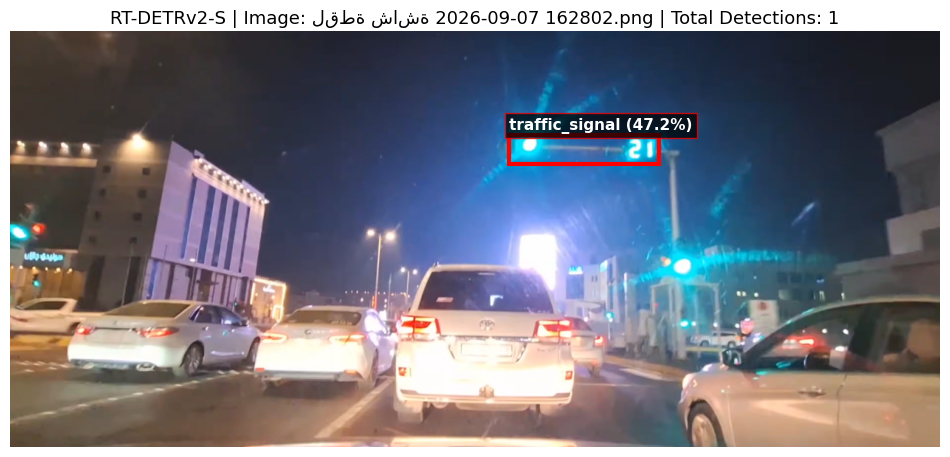

In [29]:
# ==============================================================================
# 📸 RT-DETRv2: Interactive Single-Image Inference & Testing (Google Colab)
# ==============================================================================
import os
import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import onnxruntime as ort
from google.colab import files

# 1. Class Definitions (14 ADAS Classes: IDs 0 to 13)
# --------------------------------------------------
CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

# 2. Load the Fine-Tuned ONNX Model
# --------------------------------------------------
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_night_tuned/rtdetrv2_adas_night.onnx"
if not os.path.exists(onnx_path):
    onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print("=" * 65)
print(f"Loading Model: {onnx_path}")
providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if "CUDAExecutionProvider" in ort.get_available_providers() else ["CPUExecutionProvider"]
session = ort.InferenceSession(onnx_path, providers=providers)
print(f"Active Provider: {session.get_providers()[0]}")
print("=" * 65)

# 3. Upload Image from Your Local Machine
# --------------------------------------------------
print("\nPlease select and upload an image to test:")
uploaded = files.upload()

# 4. Inference & Visualization
# --------------------------------------------------
CONFIDENCE_THRESHOLD = 0.30

for filename, content in uploaded.items():
    image = Image.open(io.BytesIO(content)).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocess: Resize to 640x640, normalize to [0, 1], planar NCHW
    img_resized = image.resize((640, 640))
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))  # HWC to CHW
    img_np = np.expand_dims(img_np, axis=0)

    # Model input: [original_width, original_height]
    orig_target_sizes = np.array([[orig_w, orig_h]], dtype=np.int64)

    # Run inference
    outputs = session.run(None, {"images": img_np, "orig_target_sizes": orig_target_sizes})
    labels, boxes, scores = outputs[0][0], outputs[1][0], outputs[2][0]

    # Setup visualization plot
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    detection_count = 0

    print(f"\n--- Detection Results for: {filename} ---")

    for label, box, score in zip(labels, boxes, scores):
        if score >= CONFIDENCE_THRESHOLD:
            cid = int(label)
            class_name = CLASS_NAMES.get(cid, f"class_{cid}")
            x1, y1, x2, y2 = box

            # Assign color according to hazard type
            if "speed" in class_name:
                box_color = "yellow"
            elif "pedestrian" in class_name or "traffic" in class_name:
                box_color = "red"
            elif "bump" in class_name or "stop" in class_name:
                box_color = "orange"
            else:
                box_color = "cyan"

            # Draw bounding box
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=3, edgecolor=box_color, facecolor="none"
            )
            ax.add_patch(rect)

            # Draw label banner
            label_text = f"{class_name} ({score * 100:.1f}%)"
            ax.text(
                x1, max(15, y1 - 8), label_text,
                color="white", fontsize=11, weight="bold",
                bbox=dict(facecolor="black", alpha=0.75, pad=3, edgecolor=box_color)
            )

            print(f"Detected: {class_name:<26} | Confidence: {score * 100:.1f}% | Box: [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")
            detection_count += 1

    if detection_count == 0:
        print(f"No objects detected above {CONFIDENCE_THRESHOLD * 100:.0f}% confidence.")

    plt.title(f"RT-DETRv2-S | Image: {filename} | Total Detections: {detection_count}", fontsize=13)
    plt.axis("off")
    plt.show()